In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('placement-dataset.csv')
df.head(3)

,cgpa,iq,placement
0,6.8,123,1
1,5.9,106,0
2,5.3,121,0


In [4]:
# check missing/null values
df.isnull().sum()

cgpa         0
iq           0
placement    0
dtype: int64

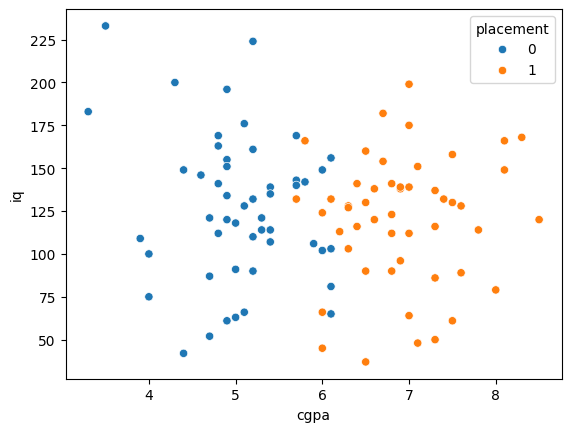

In [5]:
# visualize the data to check if it is linearly separable (applicable for classification)
sns.scatterplot(x='cgpa', y='iq', data=df, hue='placement')
plt.show()

In [6]:
# create input and output variables
x = df.iloc[:,:-1]
y = df['placement']

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
# split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

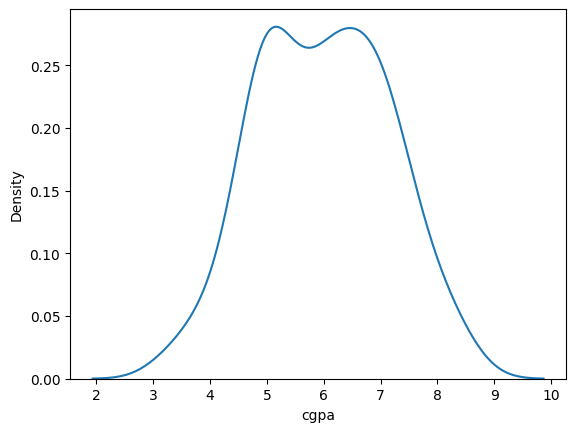

In [9]:
# now visualize KDE plotsto check whether the data is normally distributed or not
sns.kdeplot(data=df['cgpa'])
plt.show()

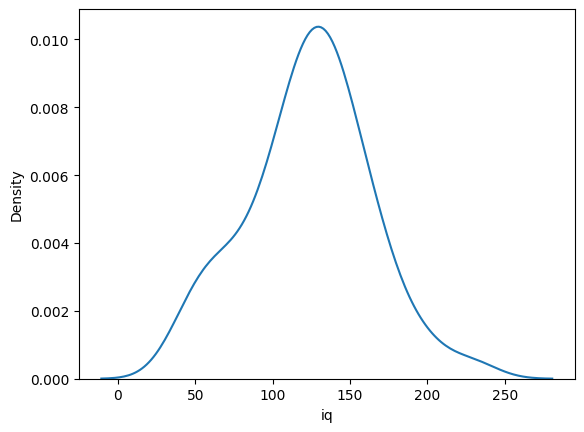

In [10]:
# now visualize KDE plotsto check whether the data is normally distributed or not
sns.kdeplot(data=df['iq'])
plt.show()

Both columns of data follows almost normal distribution, it means we can apply **Gaussian Naive Bayes** algorithm 

In [11]:
# Here only Gaussian Naive Bayes is applicable, but we will apply other types of Naive Bayes also just for practice purpose
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

Apply Gaussian Naive Bayes

In [ ]:
gnb = GaussianNB()
gnb.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[40.,40.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.5,0.5]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.533e-06
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['cgpa','iq']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[ 5.09,125.67], [ 6.89,125.75]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[ 0.41,1918.12], [ 0.39,1148.39]]"


In [16]:
# Check training and testing accuracies of Gaussian Naive Bayes
gnb.score(x_train, y_train)*100, gnb.score(x_test, y_test)*100

(91.25, 85.0)

In [21]:
# plot decision region
# This library is neded for plotting decision boundaries
from mlxtend.plotting import plot_decision_regions

C:\Users\riazu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


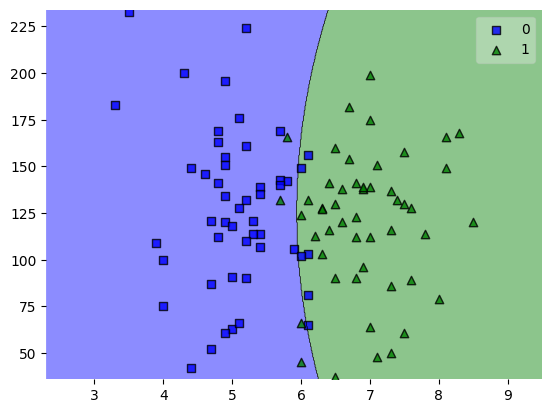

In [22]:
# Visualize decision boundaries
# input and output variables are converted into arrays bcz this library needs data in array form
plot_decision_regions(X=x.to_numpy(), y=y.to_numpy(), clf=gnb, colors='blue,green')
plt.show()

Apply Multinomial Naive Bayes

In [17]:
mnb = MultinomialNB()
mnb.fit(x_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[40.,40.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 2)","[[ 203.5,5027. ], [ 275.7,5030. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 2)","[[-3.24,-0.04], [-2.95,-0.05]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['cgpa','iq']"


In [18]:
# Check training and testing accuracies of Multinomial Naive Bayes
mnb.score(x_train, y_train)*100, mnb.score(x_test, y_test)*100

(70.0, 95.0)

C:\Users\riazu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but MultinomialNB was fitted with feature names
  warnings.warn(


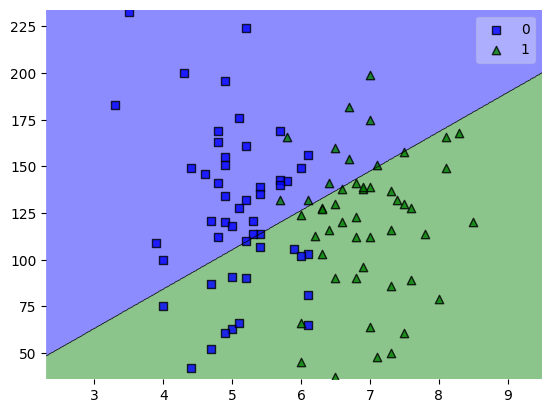

In [23]:
# Visualize decision boundaries
# input and output variables are converted into arrays bcz this library needs data in array form
plot_decision_regions(X=x.to_numpy(), y=y.to_numpy(), clf=mnb, colors='blue,green')
plt.show()

Apply Bernoulli Naive Bayes

In [19]:
bnb = BernoulliNB()
bnb.fit(x_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[40.,40.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 2)","[[40.,40.], [40.,40.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 2)","[[-0.02,-0.02], [-0.02,-0.02]]"


In [20]:
# Check training and testing accuracies of Bernoulli Naive Bayes
bnb.score(x_train, y_train)*100, bnb.score(x_test, y_test)*100

(50.0, 50.0)

C:\Users\riazu\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but BernoulliNB was fitted with feature names
  warnings.warn(


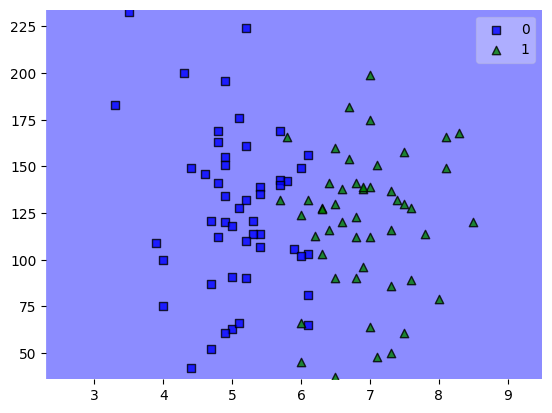

In [24]:
# Visualize decision boundaries
# input and output variables are converted into arrays bcz this library needs data in array form
plot_decision_regions(X=x.to_numpy(), y=y.to_numpy(), clf=bnb, colors='blue,green')
plt.show()